<div style="text-align:center;margin:10px 0 6px 0">
<div style="font-size:26px;font-weight:700;color:#1a1a1a;line-height:1.25">Inversión del ruteo fluvial, resolución<br>y diseño de la red de aforos en Colombia</div>
<div style="font-size:14.5px;color:#333333;margin-top:10px">Néstor O. Vásquez C.</div>
<div style="font-size:13px;color:#555555">Jitter Ingeniería SAS · Maestría en Analítica de Datos, Universidad Central, Bogotá</div>
<div style="font-size:13px;color:#555555">ORCID <a href="https://orcid.org/0009-0003-6483-790X">0009-0003-6483-790X</a> · <a href="https://github.com/nvasquezc/inversion-ruteo-fluvial-co">github.com/nvasquezc/inversion-ruteo-fluvial-co</a></div>
</div>

<div style="border-top:1.5px solid #1a1a1a;border-bottom:1.5px solid #1a1a1a;padding:10px 4px 12px 4px;margin:16px 0 18px 0;text-align:justify;font-size:14px;line-height:1.5">
<b>Resumen.</b> Con un operador de ruteo Muskingum–Cunge diferenciable, que conserva la masa por construcción, se invierte la rugosidad de Manning tramo a tramo y se mide, con la matriz de resolución, qué parte de ese campo determinan realmente los datos de caudal medio diario. En 12 redes sintéticas, tres estaciones resuelven en promedio menos de tres parámetros efectivos de 60, y solo el 13 % de los tramos tiene diag(R) &gt; 0,1. Ubicar cuatro estaciones nuevas con diseño D‑óptimo reduce el error de la rugosidad recuperada más que aforar los ríos de mayor área (11 de 12 redes; Wilcoxon p = 7×10⁻⁴), aunque el efecto es modesto (≈ 8 %). Un análisis de viabilidad sobre CAMELS‑COL encuentra 18 cuencas independientes con al menos tres estaciones anidadas, 15 de ellas sin presas, donde el método puede aplicarse a datos reales.
</div>

### Cómo está organizado

Cada sección tiene tres partes: la **idea** (qué problema resuelve el paso), el **código** (llama al paquete `ruteo_inverso`, en `src/`) y la **lectura** de la figura o tabla (qué se puede concluir y qué no). Las figuras son interactivas en Jupyter y VS Code; en GitHub se ven como imagen.

<table style="border-collapse:collapse;font-size:13.5px;margin:8px 0 6px 0">
<thead><tr>
<th style="text-align:left;padding:5px 16px;border-top:1.5px solid #1a1a1a;border-bottom:0.8px solid #1a1a1a">Inversión geofísica</th>
<th style="text-align:left;padding:5px 16px;border-top:1.5px solid #1a1a1a;border-bottom:0.8px solid #1a1a1a">Este trabajo</th></tr></thead>
<tbody>
<tr><td style="padding:4px 16px">Modelo <i>m</i> (densidad, resistividad)</td><td style="padding:4px 16px">log <i>n</i> por tramo de río</td></tr>
<tr><td style="padding:4px 16px">Operador directo <i>G</i>(<i>m</i>)</td><td style="padding:4px 16px">Ruteo Muskingum–Cunge</td></tr>
<tr><td style="padding:4px 16px">Datos <i>d</i> (anomalía, impedancia)</td><td style="padding:4px 16px">Caudal medio diario en estaciones</td></tr>
<tr><td style="padding:4px 16px">Geometría de adquisición</td><td style="padding:4px 16px">Ubicación de las estaciones</td></tr>
<tr><td style="padding:4px 16px;border-bottom:1.5px solid #1a1a1a">Profundidad de investigación</td><td style="padding:4px 16px;border-bottom:1.5px solid #1a1a1a">diag(R) por tramo</td></tr>
</tbody></table>

Las secciones 1–11 usan redes **sintéticas**, donde la verdad es conocida; la sección 12 usa datos reales (CAMELS‑COL).

In [1]:
import sys, json, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import torch
import plotly.io as pio
from IPython.display import HTML, display

from ruteo_inverso import *
from ruteo_inverso import graficos as gr
from ruteo_inverso.graficos import km2, tabla, verificacion

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The kopts argument")   # aviso de kaleido con servidor único
pio.renderers.default = "plotly_mimetype+png"                     # interactiva en Jupyter/VS Code + PNG en GitHub
pio.renderers["png"].scale = 1.6
try:
    import kaleido
    kaleido.start_sync_server()                                   # un solo Chrome para toda la sesión
except Exception:
    pass

display(HTML(verificacion(f"torch {torch.__version__} · plotly {__import__('plotly').__version__}", True)))

## 1. La red fluvial como grafo dirigido

**Idea.** Un río es un árbol dirigido: cada tramo drena hacia un único tramo aguas abajo, hasta la salida. Con **orden topológico** (todo tramo aguas arriba tiene un índice menor que el tramo al que drena), la matriz de adyacencia $A$, con $A_{ji}=1$ si el tramo $i$ drena en $j$, es triangular inferior estricta, y el caudal de toda la red en cada instante sale de una sola sustitución hacia adelante.

Cada tramo tiene longitud $L$, pendiente $S_0$, ancho $B$ y área local de aporte. Ancho y pendiente siguen leyes de potencia del área de drenaje (geometría hidráulica de Leopold y Maddock), con coeficientes ilustrativos, **no calibrados para Colombia**.

Propiedad,Valor
Tramos,60
Área de drenaje en la salida,18 706 km²
Longitud de tramo,7.9–32.5 km
Pendiente S₀,3.1e-04–3.9e-03 m m⁻¹


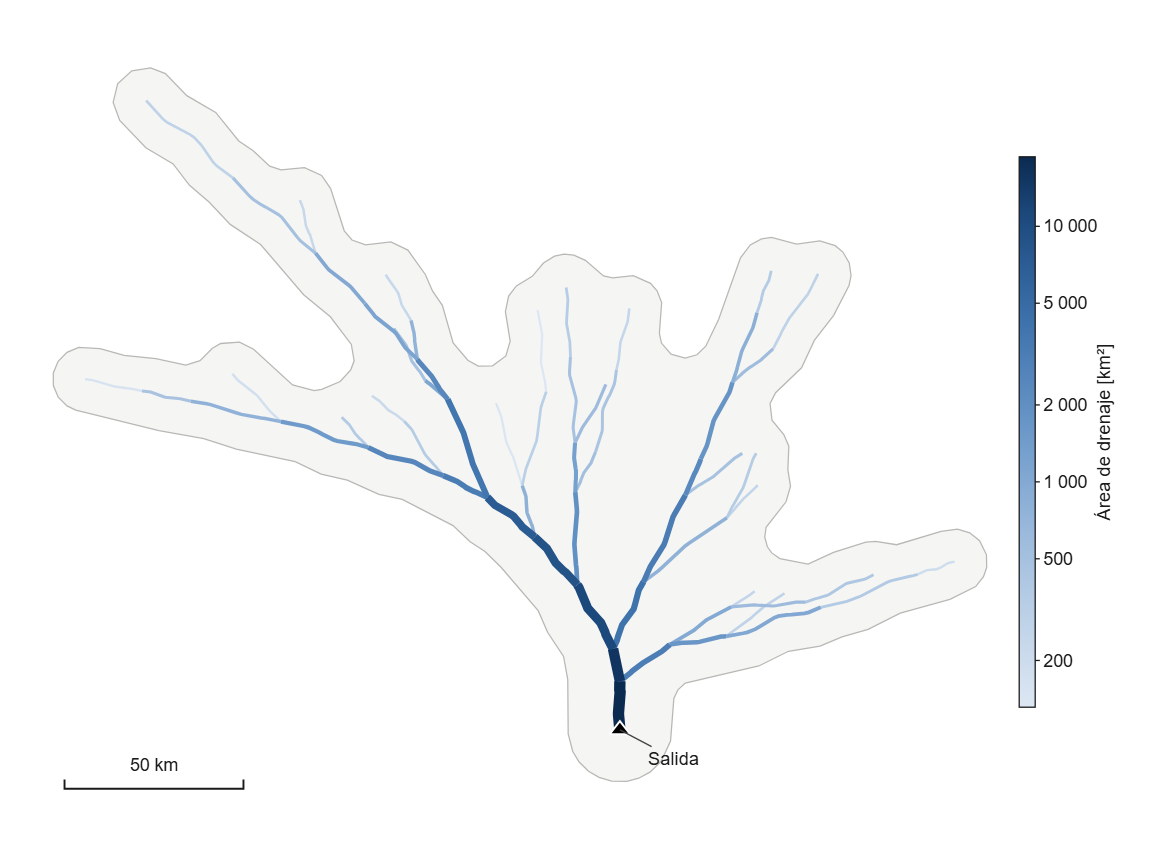

In [2]:
red = red_sintetica(n_tramos=60, semilla=0)
A_dren = red.area_drenaje_km2()
salida = int(np.where(red.aguas_abajo < 0)[0][0])
A = red.adyacencia()

display(HTML(tabla(["Propiedad", "Valor"], [
    ["Tramos", red.n],
    ["Área de drenaje en la salida", km2(A_dren[salida])],
    ["Longitud de tramo", f"{red.longitud_m.min()/1e3:.1f}–{red.longitud_m.max()/1e3:.1f} km"],
    ["Pendiente S₀", f"{red.pendiente.min():.1e}–{red.pendiente.max():.1e} m m⁻¹"],
], titulo="Red sintética de referencia.")))
display(HTML(verificacion("A es triangular inferior estricta", bool(torch.all(torch.triu(A) == 0)))
             + verificacion(f"{int(A.sum())} conexiones = n − 1 (árbol)", int(A.sum()) == red.n - 1)))

gr.figura_red(red, salida).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 1.</b> Red sintética de 60 tramos dibujada en planta. El grosor y el color de cada cauce crecen con el área de drenaje; el sombreado gris es la cuenca. La longitud de cada tramo es la del modelo; la orientación de los tributarios es solo una elección de dibujo (la red no tiene coordenadas reales).</p>

## 2. El forzamiento: aporte lateral de cada subcuenca

**Idea.** Cada tramo recibe agua de su subcuenca local. En el sintético se generan tormentas con cobertura espacial parcial; cada subcuenca convierte la lluvia en escorrentía con un embalse lineal, más un caudal base. Si toda la cuenca recibiera la misma lluvia al mismo tiempo, sería imposible distinguir un tramo lento de otro rápido: la **variabilidad espacio‑temporal** del aporte es la que, en principio, hace identificables los parámetros. Con datos reales, este aporte vendrá de un modelo lluvia‑escorrentía (p. ej., un LSTM forzado con CHIRPS y MSWX).

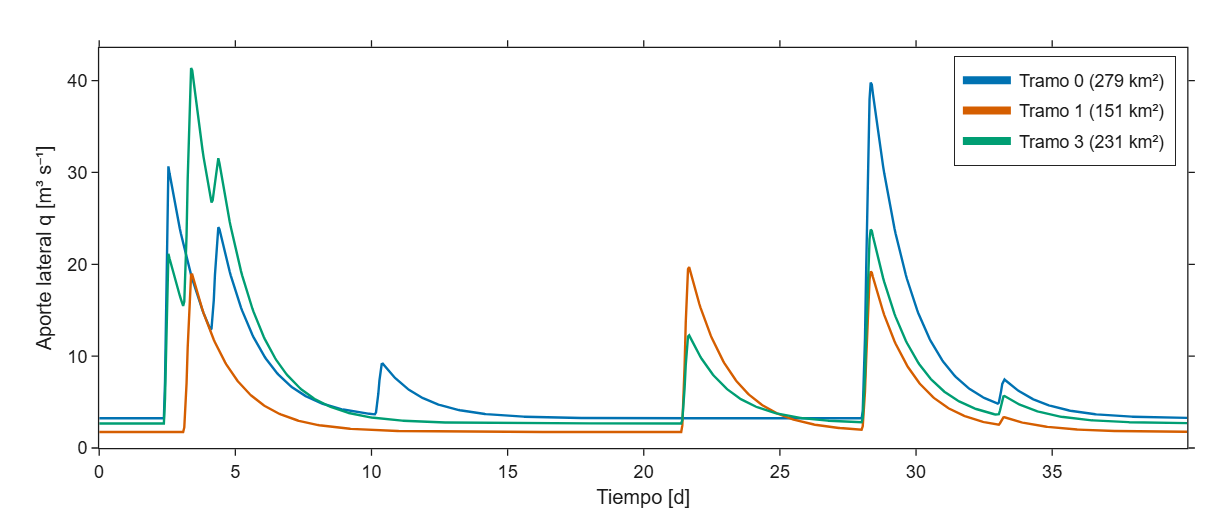

In [3]:
PASOS_DIA, DIAS = 24, 40
q = aporte_lateral_sintetico(red, dias=DIAS, pasos_por_dia=PASOS_DIA, semilla=0)
t_dias = np.arange(q.shape[0]) / PASOS_DIA
cabeceras = [i for i in range(red.n) if i not in set(red.aguas_abajo)][:3]
gr.figura_aporte(t_dias, q.numpy(), cabeceras, A_dren).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 2.</b> Aporte lateral horario en tres subcuencas de cabecera durante 40 días. Las tormentas sintéticas no cubren toda la cuenca: el evento del día 21 llega a dos de las tres subcuencas con intensidades distintas.</p>

## 3. El operador directo: ruteo Muskingum–Cunge diferenciable

**Idea.** El agua que entra a un tramo se **retrasa** y se **atenúa**. Muskingum describe cada tramo con $K$ (tiempo de tránsito) y $X$ (peso de la entrada en el almacenamiento):

$$S = K\,[X\,I + (1-X)\,O], \qquad O_t = c_0 I_t + c_1 I_{t-1} + c_2 O_{t-1},$$

$$c_0=\frac{\Delta t-2KX}{D},\quad c_1=\frac{\Delta t+2KX}{D},\quad c_2=\frac{2K(1-X)-\Delta t}{D},\quad D=2K(1-X)+\Delta t .$$

**Cunge** conecta $K$ y $X$ con la física del cauce. En un canal rectangular ancho, Manning da la profundidad, la velocidad y la celeridad de la onda:

$$Q=\tfrac{1}{n}B\,h^{5/3}S_0^{1/2}\;\Rightarrow\; c=\tfrac{5}{3}v,\qquad K=\frac{L}{c},\qquad X=\tfrac12\Big(1-\frac{Q}{B S_0 c L}\Big).$$

La rugosidad $n$ es el parámetro desconocido: un cauce rugoso es más lento, $K$ crece y el pico llega más tarde y más atenuado. Todo está escrito en PyTorch, así que $\partial Q/\partial n$ se obtiene por diferenciación automática, igual que el operador de impedancia del MT‑1D.

La entrada a cada tramo es la salida de sus afluentes más el aporte lateral, $I_t = A\,O_t + q_t$; al sustituirla queda el sistema triangular $(\mathbb{I} - \mathrm{diag}(c_0)A)\,O_t = c_0\,q_t + c_1 I_{t-1} + c_2 O_{t-1}$, que se factoriza una vez y se reutiliza en cada paso.

<div style="border-left:2px solid #9a9a9a;padding:2px 0 2px 14px;margin:8px 0 14px 0;color:#333333">

**Simplificación.** La celeridad se evalúa en un caudal de referencia fijo (el medio de cada tramo): los coeficientes no cambian en el tiempo y el ruteo es lineal. La versión no lineal es el experimento E02.

</div>

In [4]:
q_ref = caudal_referencia(red, q)
modelo = MuskingumCunge(red, q_ref, dt_s=3600.0)
log_n_verdadero = rugosidad_verdadera(red, semilla=0)
co = modelo.coeficientes(log_n_verdadero)
diag_c = modelo.diagnostico_courant(log_n_verdadero)

display(HTML(tabla(["Parámetro", "Mínimo", "Máximo"], [
    ["n de Manning (verdadero)", f"{log_n_verdadero.exp().min():.3f}", f"{log_n_verdadero.exp().max():.3f}"],
    ["K [h]", f"{co.K.min()/3600:.1f}", f"{co.K.max()/3600:.1f}"],
    ["X", f"{co.X.min():.2f}", f"{co.X.max():.2f}"],
], titulo="Parámetros de Muskingum–Cunge en la red verdadera.")))
display(HTML(verificacion("c₀ + c₁ + c₂ = 1 en todos los tramos",
                          bool(torch.allclose(co.c0 + co.c1 + co.c2, torch.ones(red.n, dtype=torch.float64))))
             + verificacion(f"tramos con c₂ < 0: {diag_c['frac_c2_negativo']:.0%}", diag_c["frac_c2_negativo"] == 0)))

Parámetro,Mínimo,Máximo
n de Manning (verdadero),0.020,0.064
K [h],1.2,10.5
X,0.05,0.38


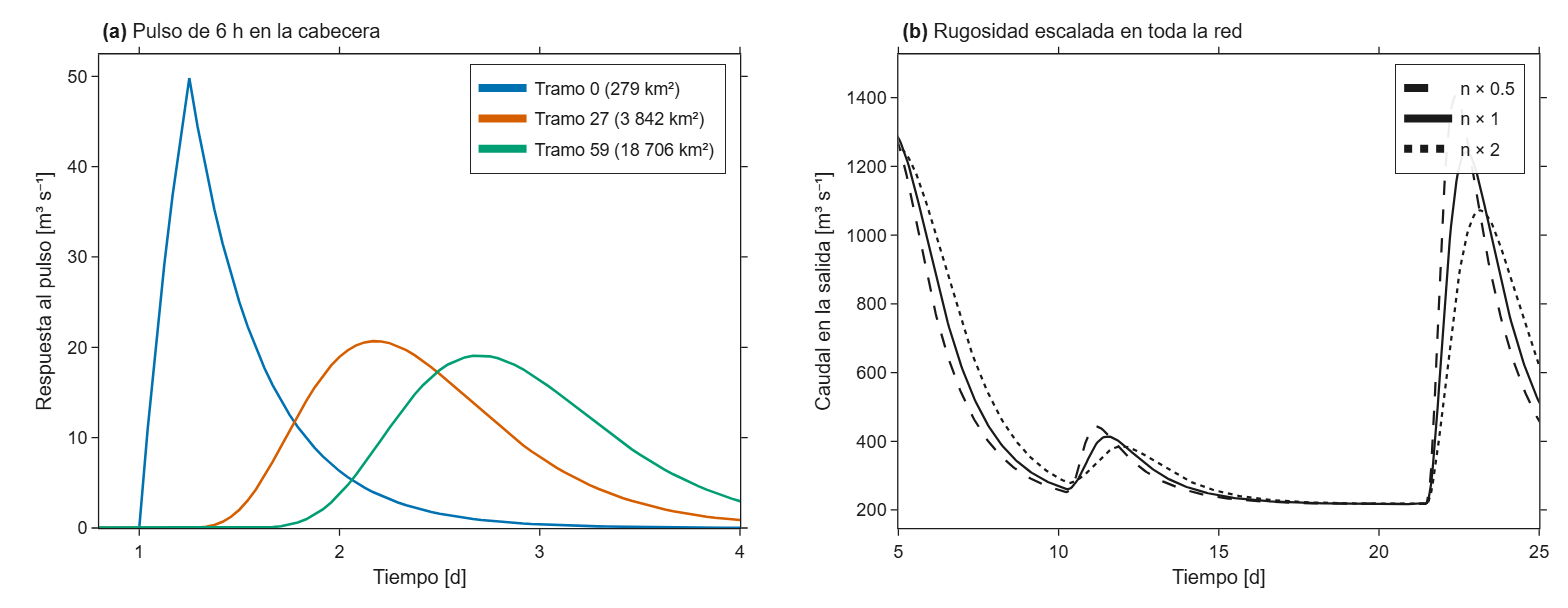

In [5]:
O, I, S = modelo.rutear(log_n_verdadero, q, devolver_estado=True)

camino = [cabeceras[0]]                       # de una cabecera a la salida
while red.aguas_abajo[camino[-1]] >= 0:
    camino.append(int(red.aguas_abajo[camino[-1]]))
mostrar = [camino[0], camino[len(camino) // 2], camino[-1]]

q_pulso = q[:1].repeat(10 * PASOS_DIA, 1).clone()   # caudal base + pulso de 6 h en la cabecera
q_pulso[PASOS_DIA:PASOS_DIA + 6, camino[0]] += 100.0
O_pulso = modelo.rutear(log_n_verdadero, q_pulso)
exceso = (O_pulso - O_pulso[0]).numpy()
t10 = np.arange(q_pulso.shape[0]) / PASOS_DIA
vol = [float(exceso[:, i].sum() * 3600 / 1e6) for i in mostrar]

salidas_n = {f: modelo.rutear(log_n_verdadero + np.log(f), q)[:, salida].numpy() for f in (0.5, 1.0, 2.0)}
display(HTML(verificacion("volumen del pulso en los tres puntos [hm³]: " + ", ".join(f"{v:.3f}" for v in vol)
                          + " (esperado 2.160)", max(abs(v - 2.16) for v in vol) < 1e-3)))
gr.figura_ruteo(t10, exceso, mostrar, A_dren, t_dias, salidas_n).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 3.</b> (a) Respuesta a un pulso de 100 m³ s⁻¹ durante 6 h aplicado en la cabecera, observada en tres puntos del mismo camino hacia la salida: el pulso llega más tarde, más bajo y más ancho, con el mismo volumen (2,16 hm³). (b) Caudal en la salida al multiplicar la rugosidad de todos los tramos por 0,5, 1 y 2: el pico se desplaza unas horas y cambia de altura, pero el hidrograma conserva su forma. Es la primera señal de que el caudal es poco sensible a <i>n</i>.</p>

## 4. Conservación de masa por construcción

**Idea.** En una red neuronal "informada por la física" típica (PINN), la física entra como una penalización y se cumple solo aproximadamente. Aquí es una propiedad de la arquitectura: como $c_0+c_1+c_2=1$, el esquema cumple exactamente la continuidad discreta

$$\Delta t\sum_t \tfrac12\big[(I_t+I_{t+1})-(O_t+O_{t+1})\big] = S_T - S_0 ,$$

en cada tramo y en toda la red, para cualquier valor de $n$.

Término,Volumen [km³]
Entra (aporte lateral),1.567855
Sale por la salida,1.567682
Cambio de almacenamiento ΔS,+0.000173
Error de cierre relativo,1.8e-15


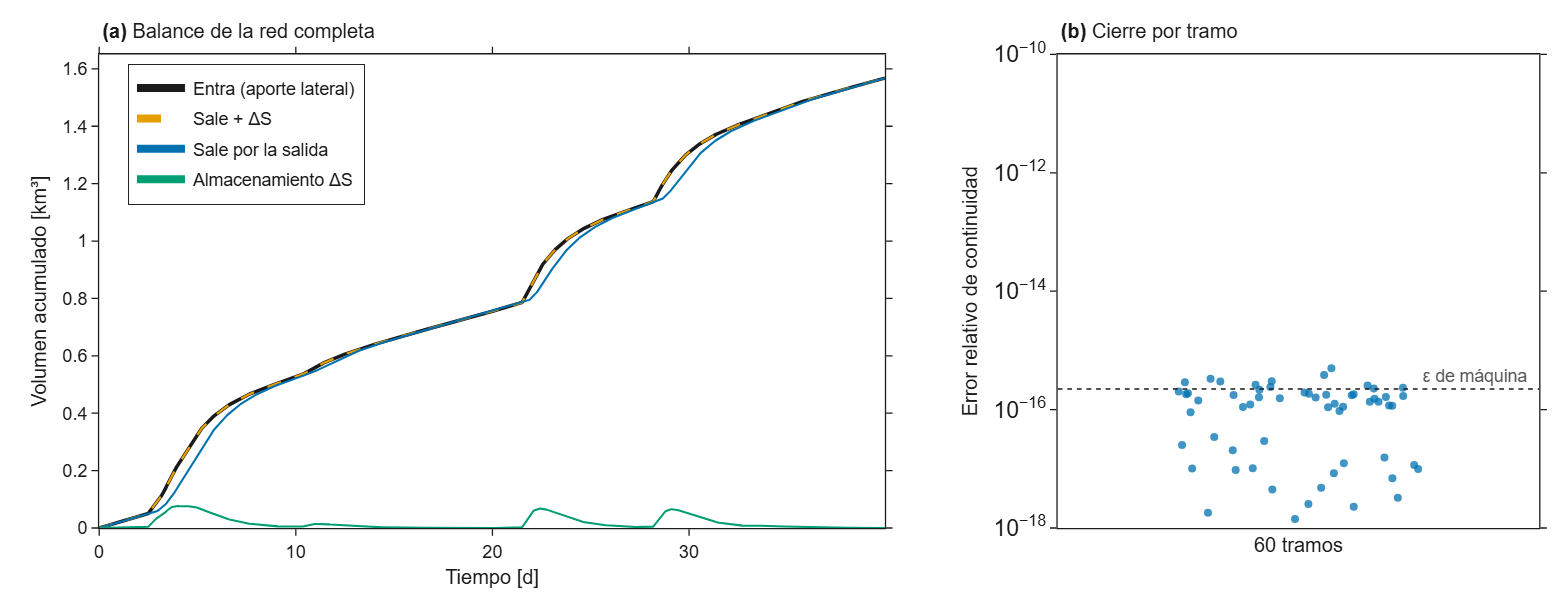

In [6]:
dt = modelo.dt
lhs = dt * 0.5 * ((I[:-1] + I[1:]) - (O[:-1] + O[1:])).sum(0)
err_tramo = ((lhs - (S[-1] - S[0])).abs() / (dt * I.sum(0))).numpy()

def acumulado(serie):                                   # integral trapezoidal acumulada, en km³
    return np.concatenate([[0.0], np.cumsum(0.5 * (serie[:-1] + serie[1:]) * dt)]) / 1e9

entra = acumulado(q.sum(1).numpy())
sale = acumulado(O[:, salida].numpy())
dS = (S.sum(1) - S[0].sum()).numpy() / 1e9
cierre = abs(entra[-1] - sale[-1] - dS[-1]) / entra[-1]

display(HTML(tabla(["Término", "Volumen [km³]"], [
    ["Entra (aporte lateral)", f"{entra[-1]:.6f}"], ["Sale por la salida", f"{sale[-1]:.6f}"],
    ["Cambio de almacenamiento ΔS", f"{dS[-1]:+.6f}"], ["Error de cierre relativo", f"{cierre:.1e}"],
], titulo="Balance de masa de la red completa en 40 días.")))
gr.figura_masa(t_dias, entra, sale, dS, err_tramo).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 4.</b> (a) Volumen acumulado que entra a la red por aporte lateral, el que sale por la salida, el almacenado en los cauces y la suma de estos dos últimos (línea discontinua), que coincide con el que entra durante todo el periodo. (b) Error relativo de continuidad de cada uno de los 60 tramos, en escala logarítmica, frente a la precisión de máquina (línea punteada).</p>

## 5. Observaciones sintéticas: pocas estaciones y datos diarios

**Idea.** Se imita la situación colombiana: tres estaciones (la salida y las dos subcuencas de mayor área, como suele ubicarse una red real), **caudal medio diario** (lo que publican IDEAM y CAMELS‑COL, aunque el ruteo se resuelva cada hora) y un error de observación del 5 % más 0,5 m³ s⁻¹, como incertidumbre de la curva de gasto. Luego se olvida la verdad y se intenta recuperarla solo con estos datos.

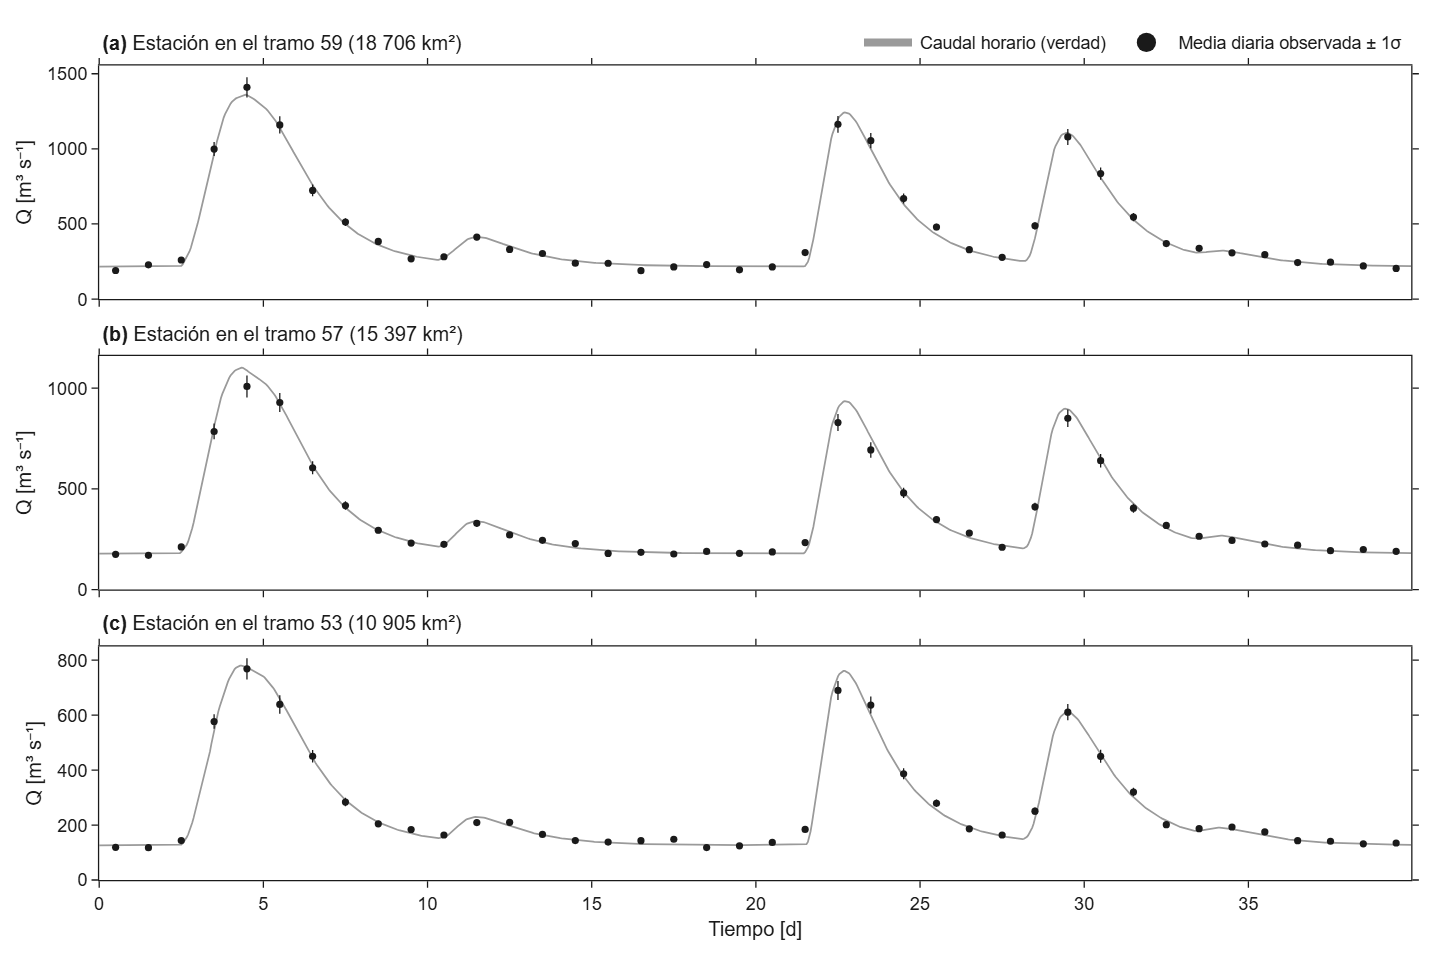

In [7]:
estaciones = [salida] + [int(i) for i in np.argsort(-A_dren) if i != salida][:2]
d_obs, sigma = sintetizar_observaciones(modelo, log_n_verdadero, q, estaciones, PASOS_DIA,
                                        ruido_rel=0.05, piso_m3s=0.5, semilla=0)
problema = ProblemaInverso(modelo, q, estaciones, PASOS_DIA, d_obs, sigma, dias_calentamiento=3)
dias = np.arange(d_obs.shape[0]) + 0.5
N = problema.n_datos
display(HTML(verificacion(f"{len(estaciones)} estaciones × {d_obs.shape[0]} días → N = {N} datos usados "
                          "(sin los 3 días de calentamiento)", True)))
gr.figura_observaciones(t_dias, O.numpy(), dias, d_obs.numpy(), sigma.numpy(), estaciones, A_dren).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 5.</b> Caudal horario verdadero (gris) y media diaria observada con su desviación estándar (puntos negros) en las tres estaciones: (a) la salida y (b, c) las dos subcuencas de mayor área. Al promediar por día se pierde la forma de los picos, que es justamente donde está la información sobre el tiempo de tránsito.</p>

## 6. Sensibilidad: ¿cuánto «ven» los datos a la rugosidad?

**Idea.** Antes de invertir hay que comprobar que los datos contienen información sobre el parámetro. Primero se escala la rugosidad de toda la red y se mide el desajuste $\phi_d=\sum (d-d_{obs})^2/\sigma^2$; si el modelo es correcto, $\phi_d \approx N$ con desviación $\sqrt{2N}$. Después se calcula el Jacobiano $J=\partial d/\partial \log n$ por diferenciación automática (`torch.func.jacfwd`).

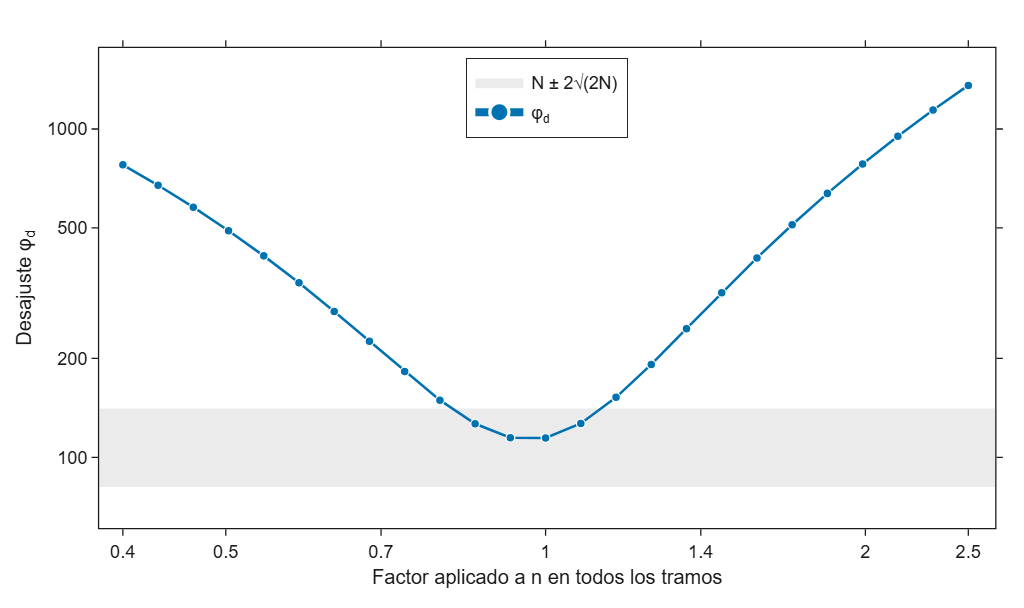

In [8]:
factores = np.exp(np.linspace(np.log(0.4), np.log(2.5), 25))
phis = np.array([float(problema.phi_d(log_n_verdadero + np.log(f))) for f in factores])
gr.figura_barrido(factores, phis, N).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 6.</b> Desajuste φ<sub>d</sub> al multiplicar la rugosidad de los 60 tramos por un mismo factor (ambos ejes en escala logarítmica). La franja gris es el intervalo de ajuste aceptable N ± 2√(2N) y la línea punteada marca el valor verdadero. Un cambio uniforme de ±25 % apenas sale de la franja.</p>

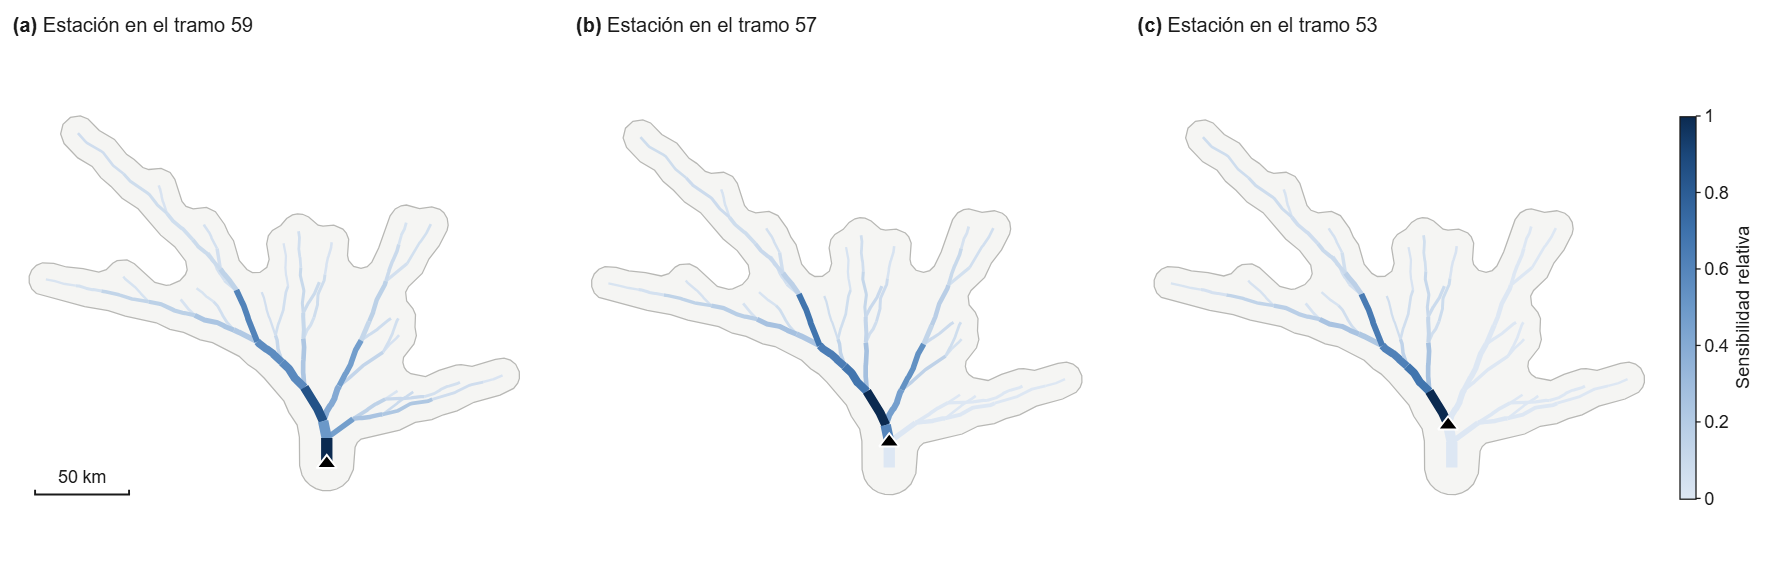

In [9]:
J = jacobiano_diario(modelo, log_n_verdadero, q, PASOS_DIA, dias_calentamiento=3)   # (días, tramos obs., parámetros)
Qd = promedio_diario(O, PASOS_DIA)[3:]
sens = ((J / (0.05 * Qd + 0.5)[..., None]) ** 2).sum(0).sqrt()                       # (tramo observado, parámetro)

fuera = ~torch.as_tensor(red.aguas_arriba_de(estaciones[1]))
s_fuera = float(J[:, estaciones[1], fuera].abs().max())
display(HTML(verificacion(f"causalidad: sensibilidad de la estación {estaciones[1]} a tramos que no drenan hacia ella = {s_fuera:g}",
                          s_fuera == 0)))
gr.figura_sensibilidad(red, [sens[e].numpy() for e in estaciones], estaciones).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 7.</b> Sensibilidad del caudal medio diario de cada estación (▲) a la rugosidad de cada tramo, ‖∂<i>d</i>/∂log <i>n</i>‖/σ sumada en el tiempo y normalizada por su máximo. Fuera de la cuenca de cada estación la sensibilidad es exactamente cero (causalidad). Dentro, se concentra en los tramos largos del cauce principal; las cabeceras, con tiempos de tránsito de pocas horas, desaparecen al promediar por día.</p>

## 7. Inversión de Tikhonov (estilo SimPEG)

**Idea.** Se busca el campo $m=\log n$ que minimiza

$$\phi(m) = \|W_d(P\,G(m)-d_{obs})\|^2 + \beta\,\big(\alpha_s\|m-m_{ref}\|^2 + \alpha_x\|D(m-m_{ref})\|^2\big),$$

con $m_{ref}=\log 0{,}035$ (valor típico de río natural según Chow, 1959; lo que diría un hidrólogo sin datos) y $D$ las diferencias entre tramos conectados. Como en SimPEG, $\beta_0$ equilibra las curvaturas de los dos términos (`BetaEstimate`), se divide entre 4 por etapa (`BetaSchedule`) y el proceso se detiene cuando $\phi_d \le N + 2\sqrt{2N}$ (`TargetMisfit`) o cuando bajar $\beta$ deja de mejorar el ajuste.

<div style="border-left:2px solid #9a9a9a;padding:2px 0 2px 14px;margin:8px 0 14px 0;color:#333333">

**Por qué la tolerancia.** Exigir $\phi_d\le N$ exacto sobreajusta el ruido la mitad de las veces. En una primera versión ocurrió en 2 de 12 redes: la inversión llevó *n* a los límites.

</div>

Etapa,β,φ_d,φ_m,Objetivo φ_d
0,9.28,116.0,1.009,140.8


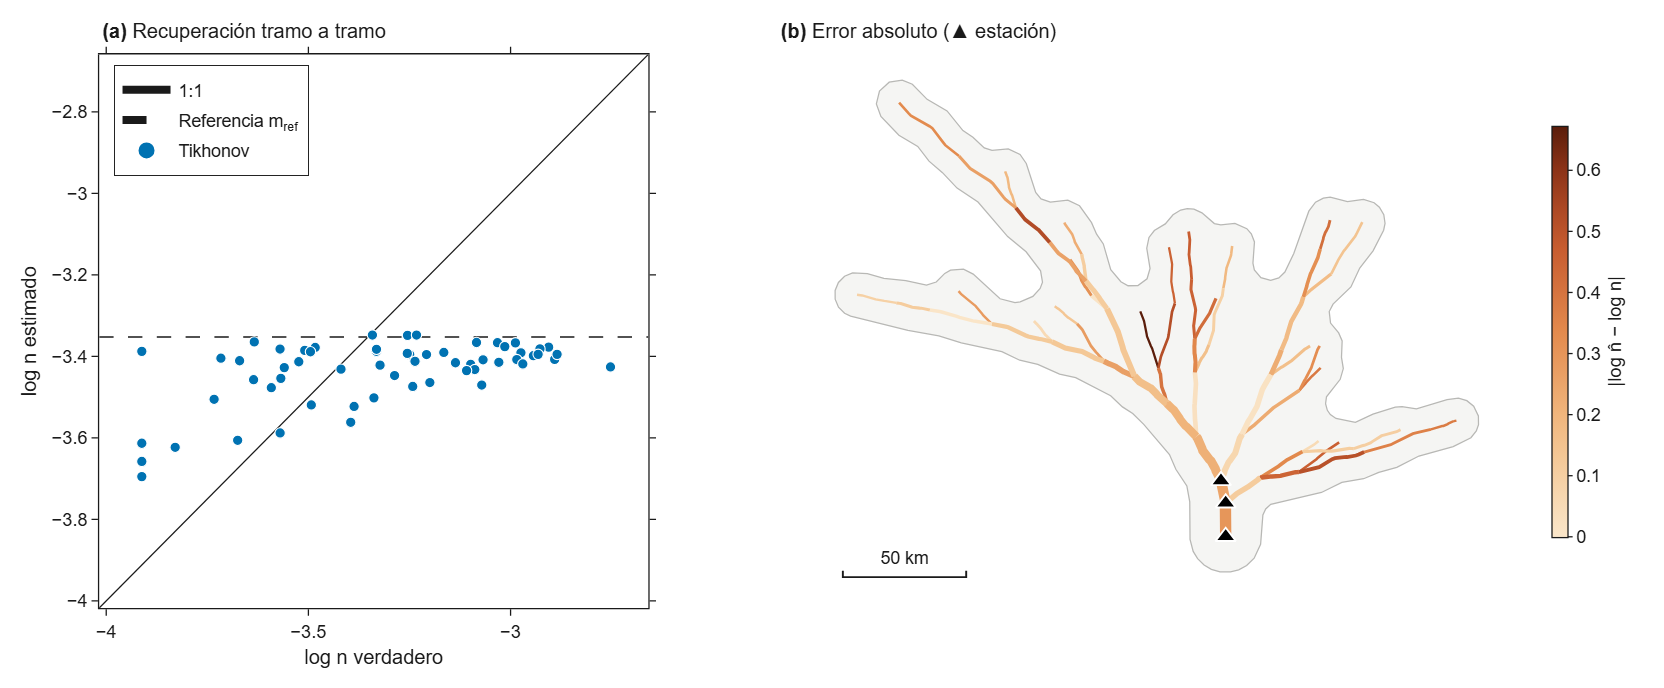

In [10]:
m_ref = torch.full((red.n,), float(np.log(0.035)), dtype=torch.float64)
D = red.laplaciano()
res_tik = invertir_tikhonov(problema, m_ref, D, alpha_s=1.0, alpha_x=1.0)
rmse = lambda m: float(((m - log_n_verdadero) ** 2).mean().sqrt())

h = res_tik.historial
display(HTML(tabla(["Etapa", "β", "φ_d", "φ_m", "Objetivo φ_d"],
                   [[x["etapa"], f"{x['beta']:.3g}", f"{x['phi_d']:.1f}", f"{x['phi_m']:.3f}", f"{x['objetivo']:.1f}"] for x in h],
                   resaltar=len(h) - 1,
                   titulo=f"Enfriamiento de β. RMSE de log n: {rmse(m_ref):.3f} sin datos, {rmse(res_tik.log_n):.3f} tras invertir.")))
error = (res_tik.log_n - log_n_verdadero).abs().numpy()
gr.figura_tikhonov(red, log_n_verdadero.numpy(), res_tik.log_n.numpy(), float(m_ref[0]), error, estaciones).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 8.</b> (a) log <i>n</i> estimado frente al verdadero en cada tramo; la línea continua es la recuperación perfecta y la discontinua el valor de referencia sin datos. Los puntos que quedan sobre la referencia son tramos donde los datos no dicen nada y decide la regularización. (b) Error absoluto por tramo; las estaciones se marcan con ▲.</p>

## 8. Matriz de resolución: ¿qué viene de los datos y qué del supuesto?

**Idea** (Menke; Aster et al.). Al linealizar alrededor de la solución,

$$H = J^\top W_d^2 J + \beta\,W_m^\top W_m, \qquad R = H^{-1}J^\top W_d^2 J, \qquad C_{post}\approx H^{-1}.$$

Si $\mathrm{diag}(R)_i \approx 1$, el tramo $i$ está resuelto por los datos; si $\approx 0$, su valor lo impone la regularización. La traza de $R$ es el número de parámetros efectivamente resueltos. Es el equivalente de la profundidad de investigación en gravimetría o MT.

<div style="border-left:2px solid #9a9a9a;padding:2px 0 2px 14px;margin:8px 0 14px 0;color:#333333">

**Alcance.** Análisis local y lineal alrededor de la solución. Para conclusiones globales se necesita muestreo (experimento E03).

</div>

Indicador,Valor
"Parámetros efectivos, tr(R)",1.66 de 60
"Tramos con diag(R) > 0,1",6
Mediana de diag(R),0.0065
Máximo de diag(R),0.279


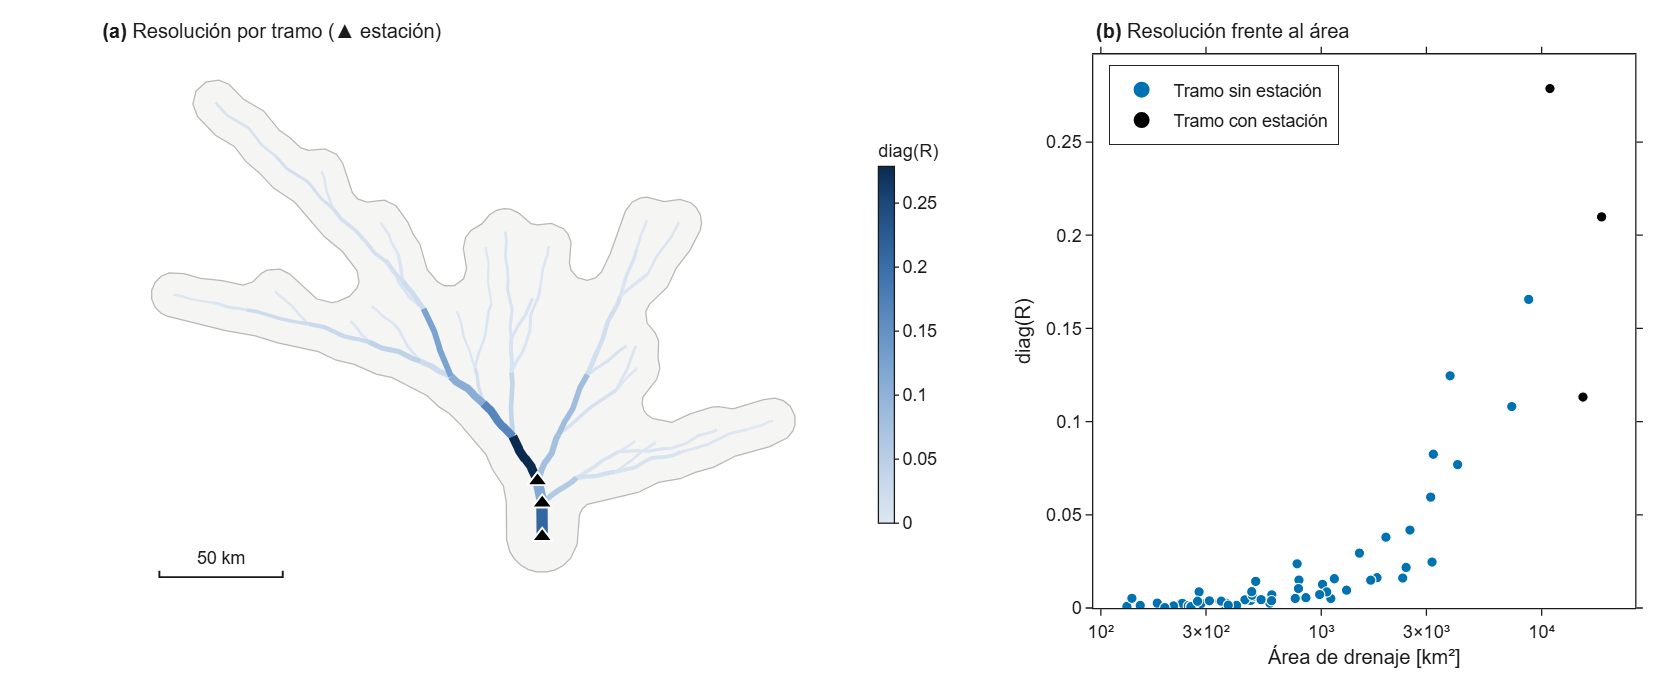

In [11]:
Wm2 = matriz_regularizacion(red.n, D, 1.0, 1.0)
J_hat = jacobiano_diario(modelo, res_tik.log_n, q, PASOS_DIA, 3)
with torch.no_grad():
    Qd_hat = promedio_diario(modelo.rutear(res_tik.log_n, q), PASOS_DIA)[3:]
reso = resolucion(J_hat[:, estaciones], (0.05 * Qd_hat.abs() + 0.5)[:, estaciones], Wm2, res_tik.beta)
dR = reso.diag_R.numpy()

display(HTML(tabla(["Indicador", "Valor"], [
    ["Parámetros efectivos, tr(R)", f"{dR.sum():.2f} de {red.n}"],
    ["Tramos con diag(R) > 0,1", f"{(dR > 0.1).sum()}"],
    ["Mediana de diag(R)", f"{np.median(dR):.4f}"],
    ["Máximo de diag(R)", f"{dR.max():.3f}"],
], titulo="Resolución con tres estaciones de caudal medio diario.")))
gr.figura_resolucion(red, dR, A_dren, estaciones).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 9.</b> (a) Diagonal de la matriz de resolución por tramo. Solo los tramos del cauce principal cercanos a las estaciones (▲) tienen resolución apreciable. (b) diag(R) frente al área de drenaje: la resolución crece con el tamaño del tramo, en línea con Bindas et al. (2024), que hallaron beneficio solo en subcuencas mayores a 2 000 km².</p>

## 9. Diseño de la red: ¿dónde poner la próxima estación?

**Idea.** Cada tramo candidato $c$ aportaría la información $F_c = J_c^\top W_d^2 J_c$. Se elige la estación que maximiza $\log\det(H + F_c)$ (**criterio D**: reduce el volumen de la incertidumbre posterior) y se repite de forma codiciosa para $k$ estaciones. El diseño se calcula con el modelo de referencia $m_{ref}$, **sin conocer la verdad**, como ocurriría antes de instalar. Se comparan tres estrategias para agregar cuatro estaciones —D‑óptimo, mayor área (la heurística tradicional) y aleatorio— reinvirtiendo con datos nuevos.

Configuración,Tramos nuevos,RMSE de log n
Red base (3 estaciones),—,0.291
+ 4 · D-óptimo,"11, 50, 55, 46",0.256
+ 4 · Mayor área,"45, 35, 54, 27",0.292
+ 4 · Aleatorio,"15, 28, 45, 35",0.291


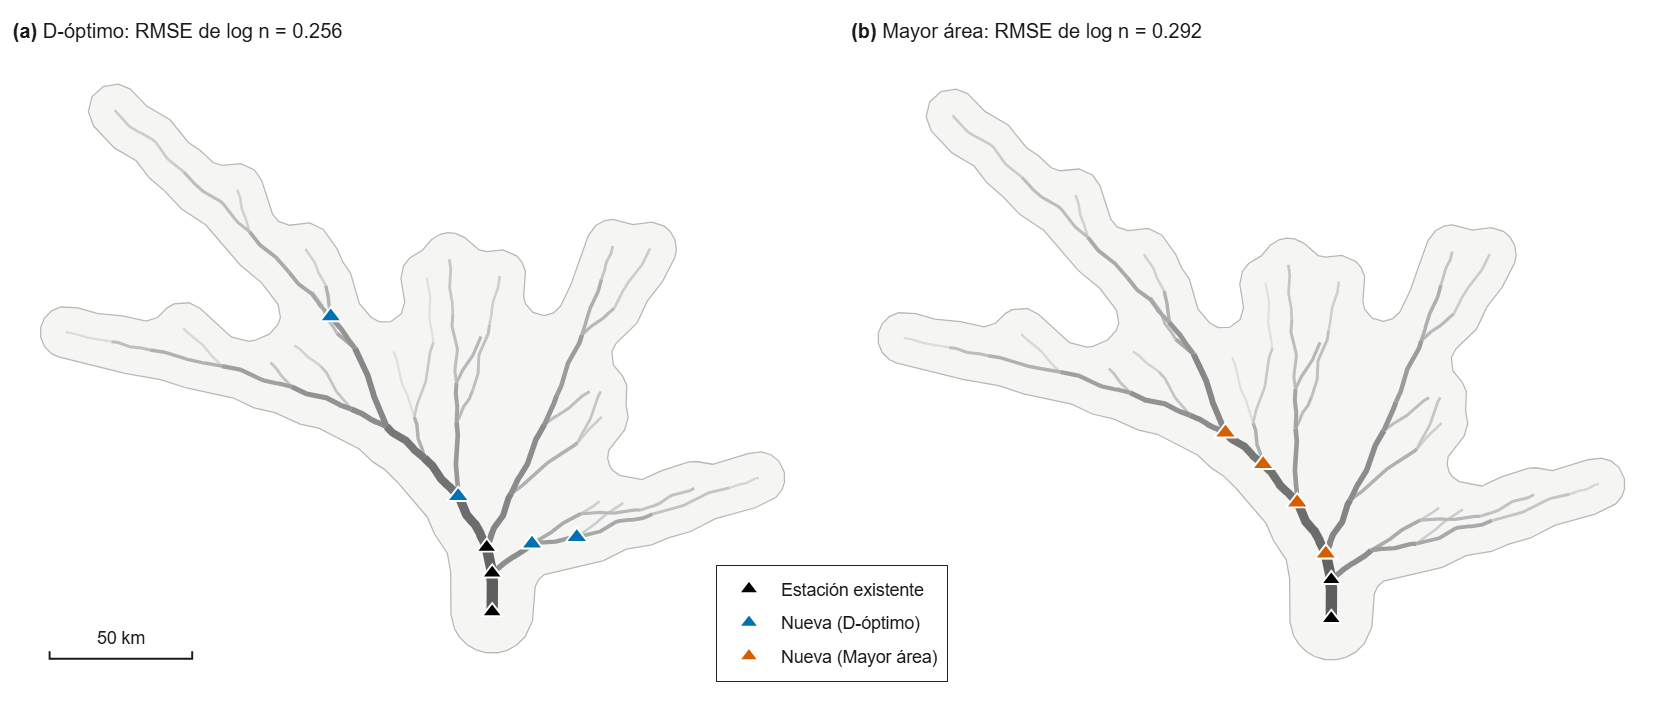

In [12]:
K_NUEVAS = 4
J_ref = jacobiano_diario(modelo, m_ref, q, PASOS_DIA, 3)
with torch.no_grad():
    Qd_ref = promedio_diario(modelo.rutear(m_ref, q), PASOS_DIA)[3:]
sig_ref = 0.05 * Qd_ref.abs() + 0.5
F = informacion_por_candidato(J_ref, sig_ref)
H_base = resolucion(J_ref[:, estaciones], sig_ref[:, estaciones], Wm2, res_tik.beta).H

d_optimo, _ = diseno_codicioso(F, H_base, K_NUEVAS, excluir=estaciones, criterio="D")
mayor_area = [int(i) for i in np.argsort(-A_dren) if i not in estaciones][:K_NUEVAS]
rng = np.random.default_rng(0)
aleatorio = [int(a) for a in rng.choice([i for i in range(red.n) if i not in estaciones], K_NUEVAS, replace=False)]

def evaluar(extra):
    est = estaciones + [int(e) for e in extra]
    d, s = sintetizar_observaciones(modelo, log_n_verdadero, q, est, PASOS_DIA, 0.05, 0.5, semilla=0)
    return rmse(invertir_tikhonov(ProblemaInverso(modelo, q, est, PASOS_DIA, d, s, 3), m_ref, D, 1.0, 1.0).log_n)

estrategias = {"D-óptimo": d_optimo, "Mayor área": mayor_area, "Aleatorio": aleatorio}
rmse_e = {k: evaluar(v) for k, v in estrategias.items()}
display(HTML(tabla(["Configuración", "Tramos nuevos", "RMSE de log n"],
                   [["Red base (3 estaciones)", "—", f"{rmse(res_tik.log_n):.3f}"]]
                   + [[f"+ 4 · {k}", ", ".join(map(str, v)), f"{rmse_e[k]:.3f}"] for k, v in estrategias.items()],
                   resaltar=1 + list(estrategias).index(min(rmse_e, key=rmse_e.get)),
                   titulo="Esta red, una sola realización del ruido.")))
gr.figura_diseno(red, A_dren, estaciones, {k: estrategias[k] for k in ("D-óptimo", "Mayor área")}, rmse_e).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 10.</b> Cuatro estaciones nuevas sobre la red base de tres (▲ negro), (a) con diseño D‑óptimo y (b) en los cuatro tramos de mayor área. La heurística de área coloca las nuevas junto a las existentes, sobre el mismo cauce, y aporta información redundante; el diseño D‑óptimo las reparte en tributarios que aún no se observan. En una sola red la diferencia puede ser pequeña o invertirse: la conclusión se toma de las 12 redes de la sección 11.</p>

## 10. Inversión neuronal no supervisada

**Idea.** En vez de estimar 60 valores sueltos, una red $f_\theta(\text{atributos del tramo}) \to \log n$ —con pendiente, área, ancho y longitud como entradas— se entrena **sin etiquetas de n**: la pérdida es solo el desajuste de datos a través del operador directo, como la inversión profunda no supervisada del MT‑1D y como Bindas et al. (2024). Su ventaja es que predice *n* en tramos sin aforo; su riesgo, que si la verdad no depende de los atributos no puede inventar esa información.

Método,φ_d / N final,RMSE de log n
Referencia (sin datos),—,0.303
Tikhonov,1.05,0.291
Neuronal no supervisada,1.01,0.666


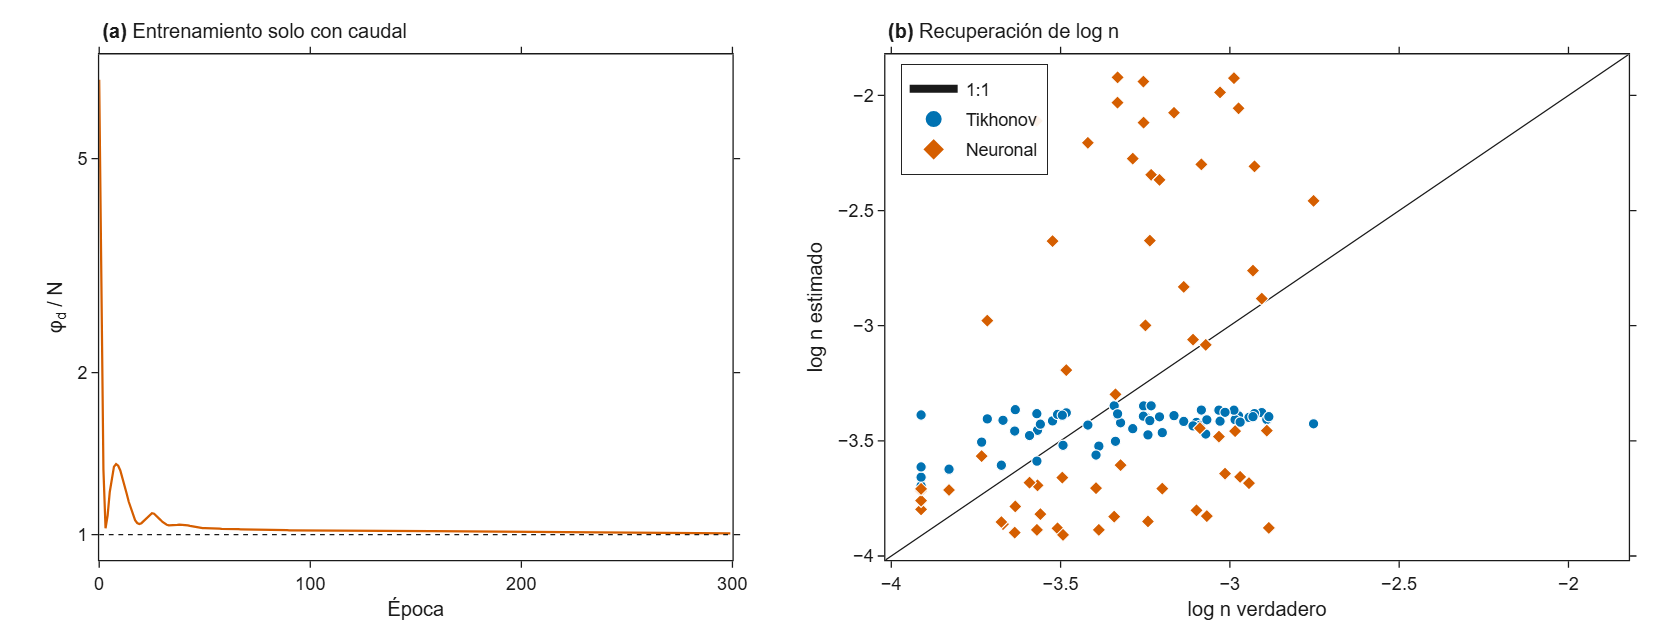

In [13]:
X_attr = torch.as_tensor(red.atributos(), dtype=torch.float64)
f_red, hist = invertir_neuronal(problema, X_attr, epocas=300, lr=1e-2, semilla=0)
with torch.no_grad():
    log_n_nn = f_red(X_attr)

display(HTML(tabla(["Método", "φ_d / N final", "RMSE de log n"], [
    ["Referencia (sin datos)", "—", f"{rmse(m_ref):.3f}"],
    ["Tikhonov", f"{res_tik.historial[-1]['phi_d'] / N:.2f}", f"{rmse(res_tik.log_n):.3f}"],
    ["Neuronal no supervisada", f"{hist[-1]:.2f}", f"{rmse(log_n_nn):.3f}"],
], titulo="Ajustar los datos no es lo mismo que recuperar el parámetro.")))
gr.figura_neuronal(np.asarray(hist), log_n_verdadero.numpy(), res_tik.log_n.numpy(), log_n_nn.numpy()).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 11.</b> (a) Desajuste normalizado φ<sub>d</sub>/N de la red neuronal durante el entrenamiento; la línea punteada es el ajuste esperado. (b) log <i>n</i> estimado frente al verdadero con Tikhonov (círculos) y con la red neuronal (rombos). Ambas ajustan los datos igual de bien, pero la red neuronal se aleja más de la verdad que no usar datos: sin regularización explícita sobre <i>n</i>, encuentra otro campo que explica los mismos caudales (no unicidad). Una sola semilla: comparación ilustrativa.</p>

## 11. Resultado agregado: experimento E01 (12 redes)

Una sola red puede engañar. `experiments/e01_identificabilidad_sintetica.py` repite las secciones 5–9 en **12 redes distintas**, con cinco sorteos aleatorios por red; aquí se leen sus resultados guardados (`results/e01_resultados.json`). Las hipótesis se fijaron antes de mirar los resultados:

- **H1.** diag(R), calculada sin conocer la verdad, predice el error (correlación de Spearman negativa).
- **H2.** El diseño D‑óptimo reduce el error más que la heurística de mayor área y que el azar (Wilcoxon pareado entre redes).

Configuración,Media,Mínimo,Máximo
Sin datos (referencia),0.307,0.274,0.362
Red base (3 estaciones),0.255,0.210,0.319
+ 4 aleatorio (media de 5),0.247,0.226,0.279
+ 4 mayor área,0.248,0.226,0.292
+ 4 D‑óptimo,0.226,0.206,0.256


Contraste,Resultado
H2: D‑óptimo < mayor área,11 de 12 redes; Wilcoxon p = 7.3e-04
Diferencia media (IC 95 % bootstrap),-0.021 [-0.031; -0.012]
H1: ρ de Spearman negativa,12 de 12 redes; mediana ρ = -0.15
"Tramos con diag(R) > 0,1 / > 0,5",13 % / 0.7 %


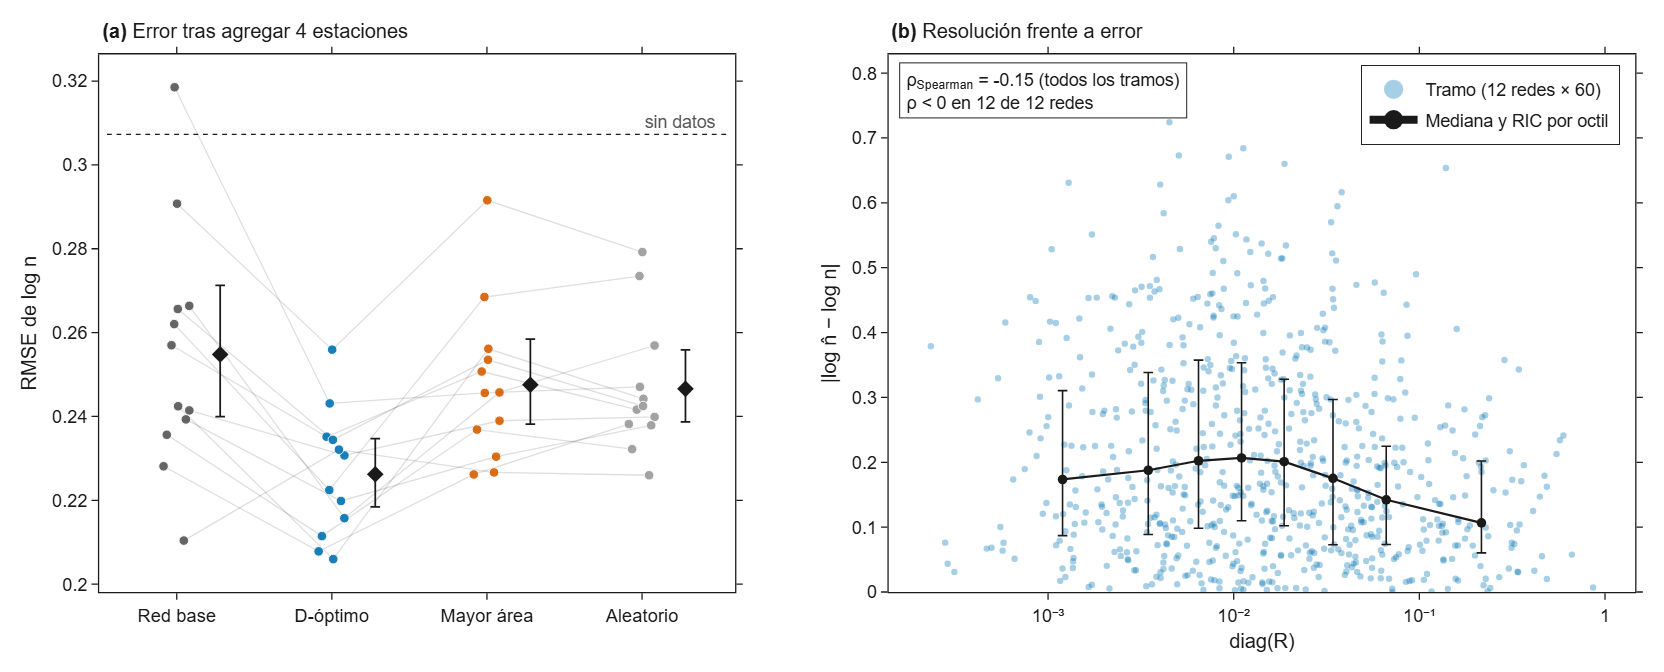

In [14]:
E01 = json.loads((RAIZ / "results" / "e01_resultados.json").read_text(encoding="utf-8"))
g, redes = E01["global"], E01["por_red"]
media = lambda r, e: np.mean([f["rmse_log_n"] for f in r["diseno"] if f["estrategia"] == e])
col = {"Sin datos (referencia)": [r["rmse_prior"] for r in redes],
       "Red base (3 estaciones)": [r["rmse_base"] for r in redes],
       "+ 4 aleatorio (media de 5)": [media(r, "aleatorio") for r in redes],
       "+ 4 mayor área": [media(r, "mayor-area") for r in redes],
       "+ 4 D‑óptimo": [media(r, "D-optimo") for r in redes]}
dopt, area = np.array(col["+ 4 D‑óptimo"]), np.array(col["+ 4 mayor área"])
rng = np.random.default_rng(0)
bs = [rng.choice(dopt - area, len(dopt)).mean() for _ in range(10000)]
rhos = np.array([r["spearman_diagR_vs_error"]["rho"] for r in redes])
dR_all = np.concatenate([r["diag_R"] for r in redes])

display(HTML(tabla(["Configuración", "Media", "Mínimo", "Máximo"],
                   [[k, f"{np.mean(v):.3f}", f"{min(v):.3f}", f"{max(v):.3f}"] for k, v in col.items()],
                   resaltar=4, titulo=f"RMSE de log n en {len(redes)} redes sintéticas de 60 tramos.")))
display(HTML(tabla(["Contraste", "Resultado"], [
    ["H2: D‑óptimo < mayor área", f"{int((dopt < area).sum())} de {len(redes)} redes; Wilcoxon p = {g['wilcoxon_D_menor_que_area']['p']:.1e}"],
    ["Diferencia media (IC 95 % bootstrap)", f"{np.mean(dopt - area):+.3f} [{np.percentile(bs, 2.5):.3f}; {np.percentile(bs, 97.5):.3f}]"],
    ["H1: ρ de Spearman negativa", f"{int((rhos < 0).sum())} de {len(rhos)} redes; mediana ρ = {np.median(rhos):.2f}"],
    ["Tramos con diag(R) > 0,1 / > 0,5", f"{100 * (dR_all > 0.1).mean():.0f} % / {100 * (dR_all > 0.5).mean():.1f} %"],
], titulo="Contraste de hipótesis.")))
gr.figura_e01(E01).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 12.</b> Experimento E01 en 12 redes sintéticas. (a) RMSE de log <i>n</i> con la red base de tres estaciones y tras agregar cuatro con cada estrategia; cada punto es una red y las líneas grises unen la misma red entre estrategias. Los rombos son la media con su intervalo de confianza del 95 % (bootstrap). La línea punteada es el error sin datos. (b) Resolución diag(R) frente al error absoluto de cada tramo (720 tramos), con la mediana y el rango intercuartil por octil de diag(R).</p>

<table style="border-collapse:collapse;font-size:13.5px;margin:6px 0 14px 0">
<thead><tr>
<th style="text-align:left;padding:5px 14px;border-top:1.5px solid #1a1a1a;border-bottom:0.8px solid #1a1a1a">Hipótesis</th>
<th style="text-align:left;padding:5px 14px;border-top:1.5px solid #1a1a1a;border-bottom:0.8px solid #1a1a1a">Veredicto</th>
<th style="text-align:left;padding:5px 14px;border-top:1.5px solid #1a1a1a;border-bottom:0.8px solid #1a1a1a">Matiz</th></tr></thead>
<tbody>
<tr><td style="padding:5px 14px;vertical-align:top"><b>H2</b> · el diseño D‑óptimo supera a mayor área y al azar</td><td style="padding:5px 14px;vertical-align:top">Apoyada</td><td style="padding:5px 14px">11 de 12 redes, p ≈ 7×10⁻⁴. Efecto modesto (≈ 8 % menos error) y con aporte lateral perfecto.</td></tr>
<tr><td style="padding:5px 14px;vertical-align:top"><b>H1</b> · diag(R) predice el error</td><td style="padding:5px 14px;vertical-align:top">Apoyo débil</td><td style="padding:5px 14px">Dirección consistente (12 de 12 redes), magnitud pequeña (ρ ≈ −0,15). El p agrupado mezcla tramos no independientes.</td></tr>
<tr><td style="padding:5px 14px;vertical-align:top;border-bottom:1.5px solid #1a1a1a"><b>Hallazgo</b> · identificabilidad baja</td><td style="padding:5px 14px;vertical-align:top;border-bottom:1.5px solid #1a1a1a">Robusto</td><td style="padding:5px 14px;border-bottom:1.5px solid #1a1a1a">Solo ≈ 13 % de tramos con diag(R) &gt; 0,1: con caudal diario, la mayoría de <i>n</i> lo decide el supuesto previo.</td></tr>
</tbody></table>

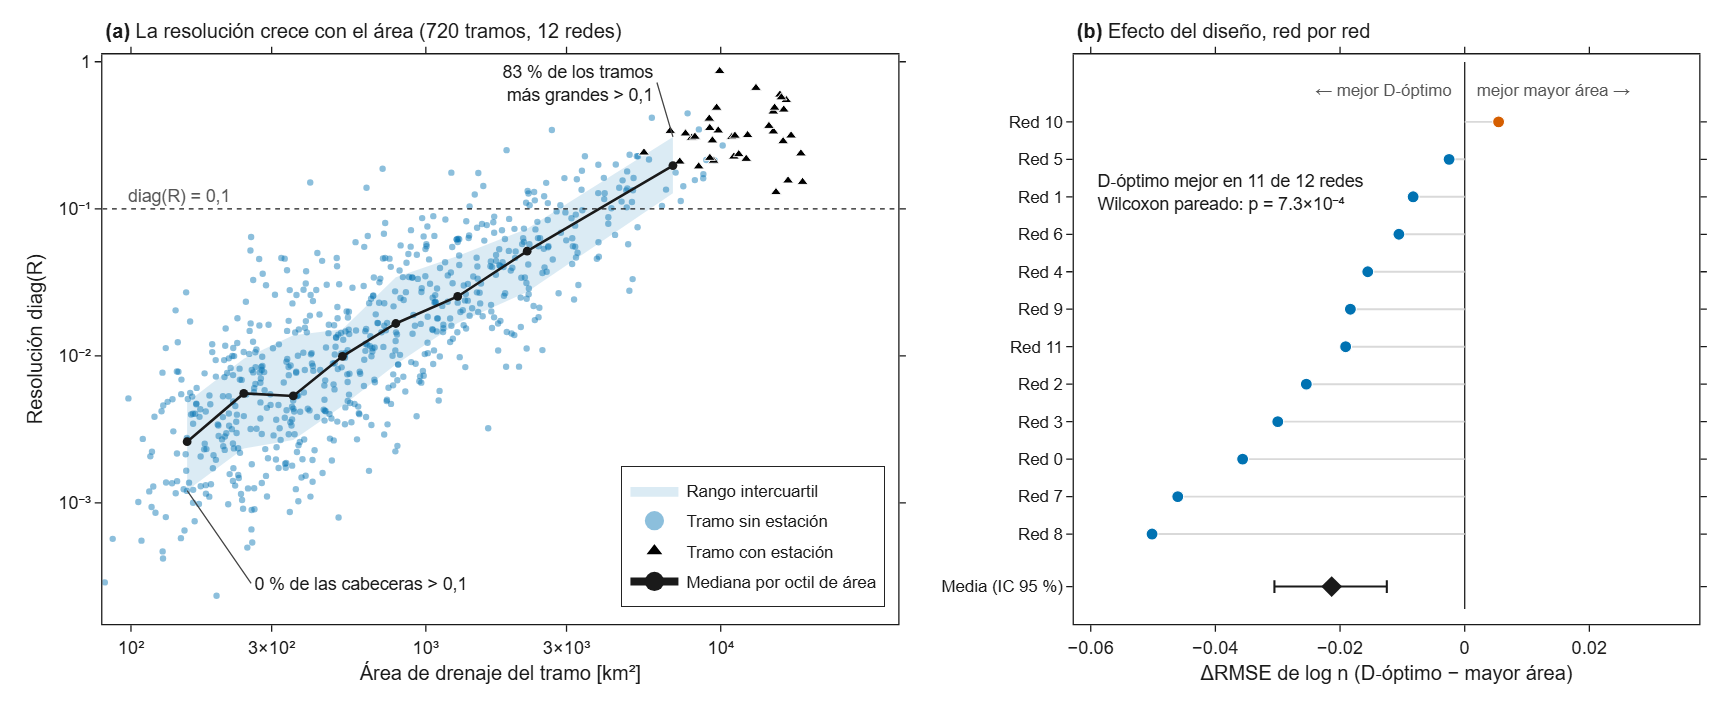

In [15]:
gr.figura_sintesis(E01).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 13.</b> Síntesis de E01. (a) Resolución diag(R) de los 720 tramos frente a su área de drenaje (ambos ejes logarítmicos), con la mediana y el rango intercuartil por octil de área; los triángulos son tramos con estación. La resolución crece casi monótonamente con el área: solo el octil de tramos más grandes supera de forma sistemática diag(R) = 0,1. (b) Diferencia de RMSE de log <i>n</i> entre el diseño D‑óptimo y la heurística de mayor área en cada red, ordenada; valores negativos favorecen al diseño D‑óptimo. El rombo es la media con su IC del 95 % (bootstrap).</p>

<div style="border-left:2px solid #9a9a9a;padding:2px 0 2px 14px;margin:8px 0 14px 0;color:#333333">

**Lo que todavía no se puede afirmar.** Nada sobre ríos colombianos reales (el modelo aún no ha invertido datos de IDEAM); nada global sobre identificabilidad (el análisis es linealizado); ni que el diseño D‑óptimo siga ganando con errores en el aporte lateral o con ruteo no lineal (E02).

</div>

## 12. Viabilidad con datos reales (Fase 0)

**Idea.** Para invertir *n* con datos reales hacen falta **estaciones anidadas**: varias estaciones sobre el mismo sistema fluvial, con registros que se solapen. Se midió con los polígonos de cuenca de CAMELS‑COL (la cuenca A está anidada en B si al menos el 90 % de su área cae dentro de B, con áreas en EPSG:9377) y se cruzaron las cuencas con las presas de GRanD v1.3. El criterio de decisión, fijado antes de mirar, era continuar si hay al menos cinco sistemas con tres o más estaciones anidadas y diez o más años de registro común.

Las tablas están en `results/fase0/`; la capa del mapa (`mapa_fase0.json`) se regenera con `scripts/preparar_mapa_fase0.py` a partir de los datos crudos descritos en `data/README.md`.

Indicador,Valor
Estaciones con otra estación aguas abajo,300 de 346
Cuencas independientes con ≥ 3 estaciones anidadas,18
"Error de área, polígono frente a tabla (mediana)",0.76 %
Estaciones con al menos una presa en su cuenca,36 de 346
Decisión,VIABLE: >= 5 sistemas utiles


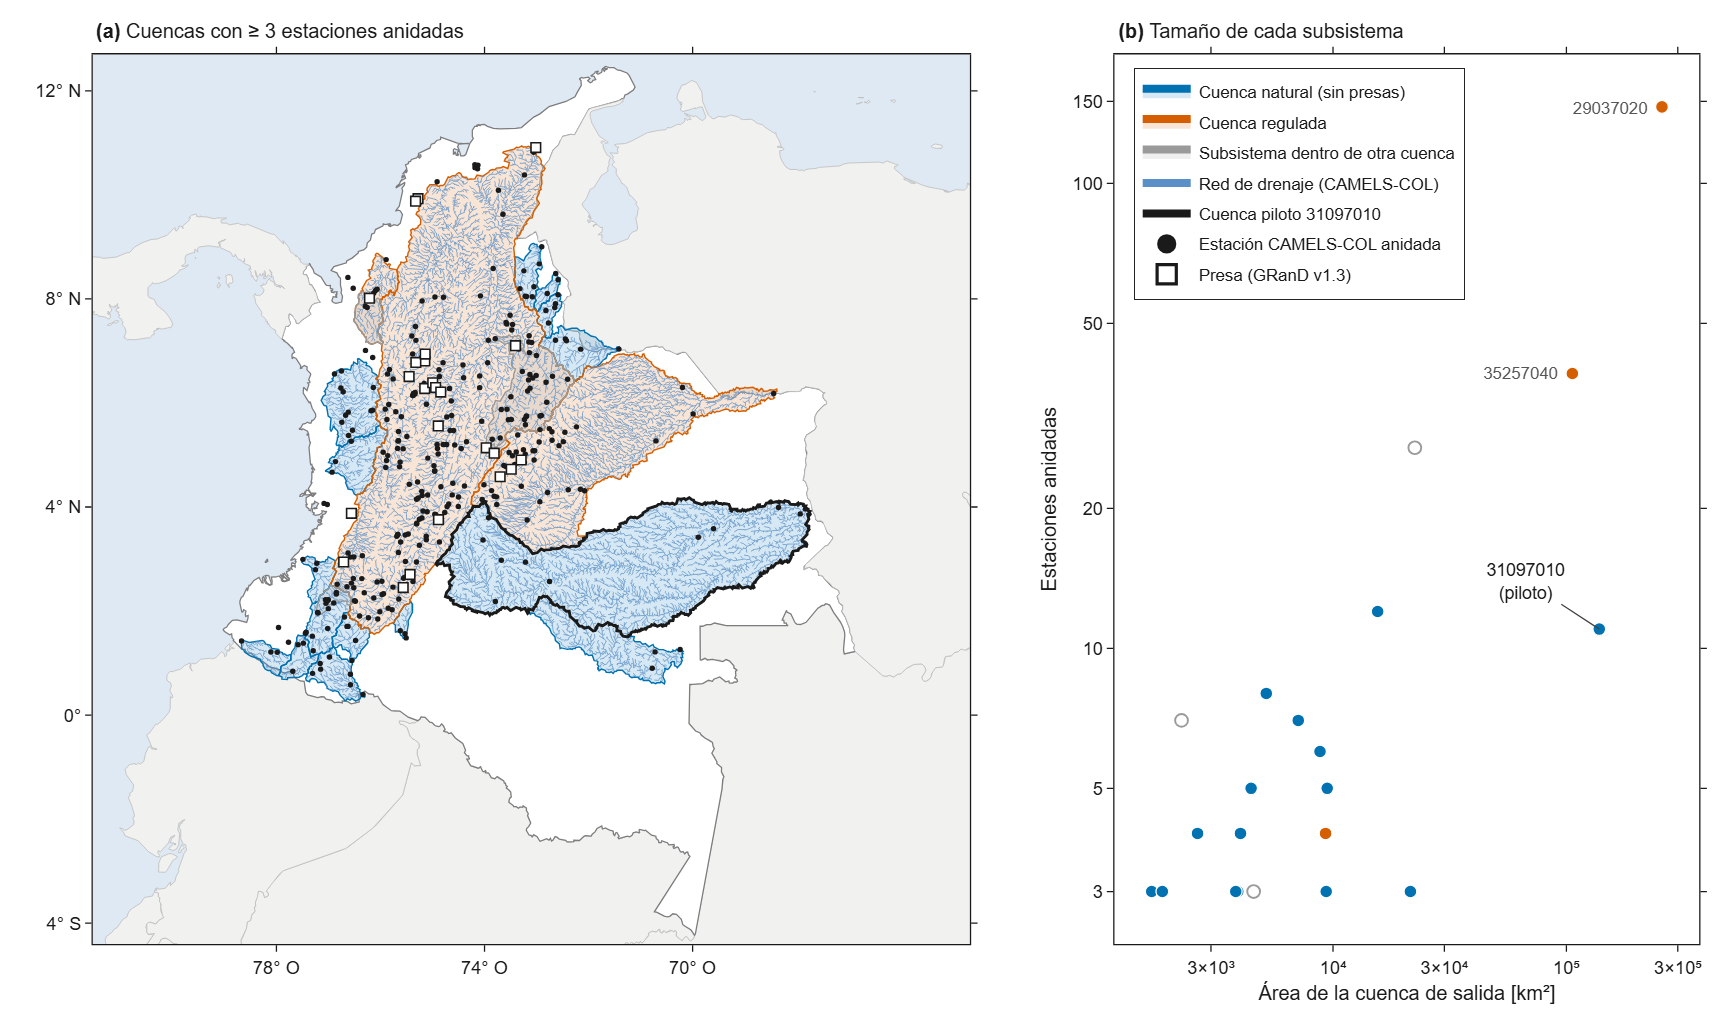

In [16]:
F0 = RAIZ / "results" / "fase0"
resumen = json.loads((F0 / "resumen_anidamiento.json").read_text(encoding="utf-8"))
sistemas = pd.read_csv(F0 / "sistemas_fase0.csv", dtype={"salida": str})
embalses = pd.read_csv(F0 / "estaciones_embalses.csv", dtype={"estacion": str})
mapa = json.loads((F0 / "mapa_fase0.json").read_text(encoding="utf-8"))

display(HTML(tabla(["Indicador", "Valor"], [
    ["Estaciones con otra estación aguas abajo", f"{resumen['con_estacion_aguas_abajo']} de {resumen['estaciones']}"],
    ["Cuencas independientes con ≥ 3 estaciones anidadas", resumen["sistemas_con_>=3_estaciones"]],
    ["Error de área, polígono frente a tabla (mediana)", f"{100 * resumen['mediana_error_area_poligono_vs_tabla']:.2f} %"],
    ["Estaciones con al menos una presa en su cuenca", f"{int(embalses['regulada'].sum())} de {len(embalses)}"],
    ["Decisión", resumen["decision_fase0"]],
], titulo="Fase 0 sobre CAMELS‑COL v3 y GRanD v1.3.")))
gr.figura_fase0(mapa, sistemas).show()

<p style="font-size:13px;line-height:1.45;color:#333333;margin:2px 0 18px 0;text-align:justify"><b>Figura 14.</b> (a) Cuencas de Colombia con al menos tres estaciones de CAMELS‑COL anidadas y diez años de registro común: naturales (azul), reguladas por al menos una presa de GRanD v1.3 (bermellón) y subsistemas que resultaron ser parte de otra cuenca (gris). Se muestran la red de drenaje de CAMELS‑COL, las estaciones anidadas y las presas; la línea negra gruesa delimita la cuenca piloto 31097010 (río Meta). (b) Número de estaciones anidadas frente al área de la cuenca de salida de cada subsistema; los círculos vacíos son los subsistemas contenidos en otra cuenca. Límites: Natural Earth 10 m. GRanD v1.3 (2019) no incluye Hidroituango.</p>

**Lectura.** Quince cuencas naturales quedan disponibles para la Fase 2. La piloto, 31097010 (Meta), es natural, tiene 11 estaciones, 138 309 km² y una mediana de 36 años de registro común; se eligió por escala, porque E01 mostró que con datos diarios la resolución se concentra en los tramos de mayor área. Las tres cuencas reguladas (Magdalena‑Cauca; 35257040, con Chivor, Guavio y Golillas; y el Sinú, con Urrá) exigen tratar las presas: usar subcuencas sin presas aguas arriba, tomar el caudal observado aguas abajo de la presa como condición de frontera o restringirse a periodos previos a la presa.

<div style="border-left:2px solid #9a9a9a;padding:2px 0 2px 14px;margin:8px 0 14px 0;color:#333333">

**Pendiente antes de la Fase 2.** (1) Grado de regulación (DOR = capacidad / volumen anual) para decidir si 35257040 puede tratarse como natural. (2) En el Cauca aguas abajo de Ituango se excluye 2019–2022, porque Hidroituango no está en GRanD v1.3. (3) Revisión sistemática de literatura (`docs/estado_del_arte.md`) antes de afirmar cualquier vacío. (4) Lector de las series diarias de CAMELS‑COL y modelo de aporte lateral para la cuenca piloto.

</div>